Loading Dataset and Cleaning data according to Update 1 feedback

In [273]:
import numpy as np
import pandas as pd
import textwrap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.preprocessing import OneHotEncoder

import matplotlib.pyplot as plt
import seaborn as sns

In [274]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [275]:
#Exported from Update 1 jupyter notebook
df = pd.read_csv('df_model.csv')

In [276]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NumServices,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket,Internet_DSL,Internet_Fiber,Internet_No,cluster
0,7590-VHVEG,0,0,1,0,1,0,0,0,1,0,0,0,0,2,0,1,0,29.85,29.85,0,0-3 months,1,0,0,1
1,5575-GNVDE,1,0,0,0,34,1,0,1,0,1,0,0,0,4,1,0,1,56.95,1889.50,0,25-48 months,1,0,0,1
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,0,0,0,0,4,0,1,1,53.85,108.15,1,0-3 months,1,0,0,1
3,7795-CFOCW,1,0,0,0,45,0,0,1,0,1,1,0,0,4,1,0,2,42.30,1840.75,0,25-48 months,1,0,0,1
4,9237-HQITU,0,0,0,0,2,1,0,0,0,0,0,0,0,2,0,1,0,70.70,151.65,1,0-3 months,0,1,0,2
5,9305-CDSKC,0,0,0,0,8,1,1,0,0,1,0,1,1,5,0,1,0,99.65,820.50,1,7-12 months,0,1,0,2
6,1452-KIOVK,1,0,0,1,22,1,1,0,1,0,0,1,0,4,0,1,3,89.10,1949.40,0,13-24 months,0,1,0,2
7,6713-OKOMC,0,0,0,0,10,0,0,1,0,0,0,0,0,2,0,0,1,29.75,301.90,0,7-12 months,1,0,0,1
8,7892-POOKP,0,0,1,0,28,1,1,0,0,1,1,1,1,6,0,1,0,104.80,3046.05,1,25-48 months,0,1,0,2
9,6388-TABGU,1,0,0,1,62,1,0,1,1,0,0,0,0,4,1,0,2,56.15,3487.95,0,49+ months,1,0,0,1


In [277]:
# Making Edits based on Update 1 feedback
payment_dict = {'Electronic check': 0,'Mailed check': 1,'Bank transfer': 2, 'Credit card': 3}

# Create a reverse dictionary to map ordinal values back to original categories
reverse_payment_dict = {v: k for k, v in payment_dict.items()}

# Reconstruct the original categorical 'PaymentMethod' column
df['PaymentMethod_Category'] = df['PaymentMethod'].map(reverse_payment_dict)

# Apply one-hot encoding to the reconstructed categorical column
one_hot_encoded_payment = pd.get_dummies(df['PaymentMethod_Category'], prefix='PaymentMethod')

# Drop the original ordinal 'PaymentMethod' column and the temporary 'PaymentMethod_Category'
df = df.drop(columns=['PaymentMethod', 'PaymentMethod_Category'])

# Concatenate the new one-hot encoded columns to the DataFrame
df = pd.concat([df, one_hot_encoded_payment], axis=1)

# Display the head of the updated DataFrame to verify the changes
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NumServices,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,tenure_bucket,Internet_DSL,Internet_Fiber,Internet_No,cluster,PaymentMethod_Bank transfer,PaymentMethod_Credit card,PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,0,0,1,0,0,0,0,2,0,1,29.85,29.85,0,0-3 months,1,0,0,1,False,False,True,False
1,5575-GNVDE,1,0,0,0,34,1,0,1,0,1,0,0,0,4,1,0,56.95,1889.50,0,25-48 months,1,0,0,1,False,False,False,True
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,0,0,0,0,4,0,1,53.85,108.15,1,0-3 months,1,0,0,1,False,False,False,True
3,7795-CFOCW,1,0,0,0,45,0,0,1,0,1,1,0,0,4,1,0,42.30,1840.75,0,25-48 months,1,0,0,1,True,False,False,False
4,9237-HQITU,0,0,0,0,2,1,0,0,0,0,0,0,0,2,0,1,70.70,151.65,1,0-3 months,0,1,0,2,False,False,True,False


Examining Variabled to pick for modelling

In [278]:
# Calculate the correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Display correlations with the target variable 'Churn'
churn_correlations = correlation_matrix['Churn'].sort_values(ascending=False)
print("Correlations with 'Churn' target variable:\n", churn_correlations)

Correlations with 'Churn' target variable:
 Churn                             1.000000
Internet_Fiber                    0.307463
PaymentMethod_Electronic check    0.301455
MonthlyCharges                    0.192858
PaperlessBilling                  0.191454
SeniorCitizen                     0.150541
cluster                           0.075316
StreamingTV                       0.063254
StreamingMovies                   0.060860
MultipleLines                     0.040033
PhoneService                      0.011691
gender                           -0.008545
NumServices                      -0.031052
DeviceProtection                 -0.066193
OnlineBackup                     -0.082307
PaymentMethod_Mailed check       -0.090773
PaymentMethod_Bank transfer      -0.118136
Internet_DSL                     -0.124141
PaymentMethod_Credit card        -0.134687
Partner                          -0.149982
Dependents                       -0.163128
TechSupport                      -0.164716
OnlineSecu

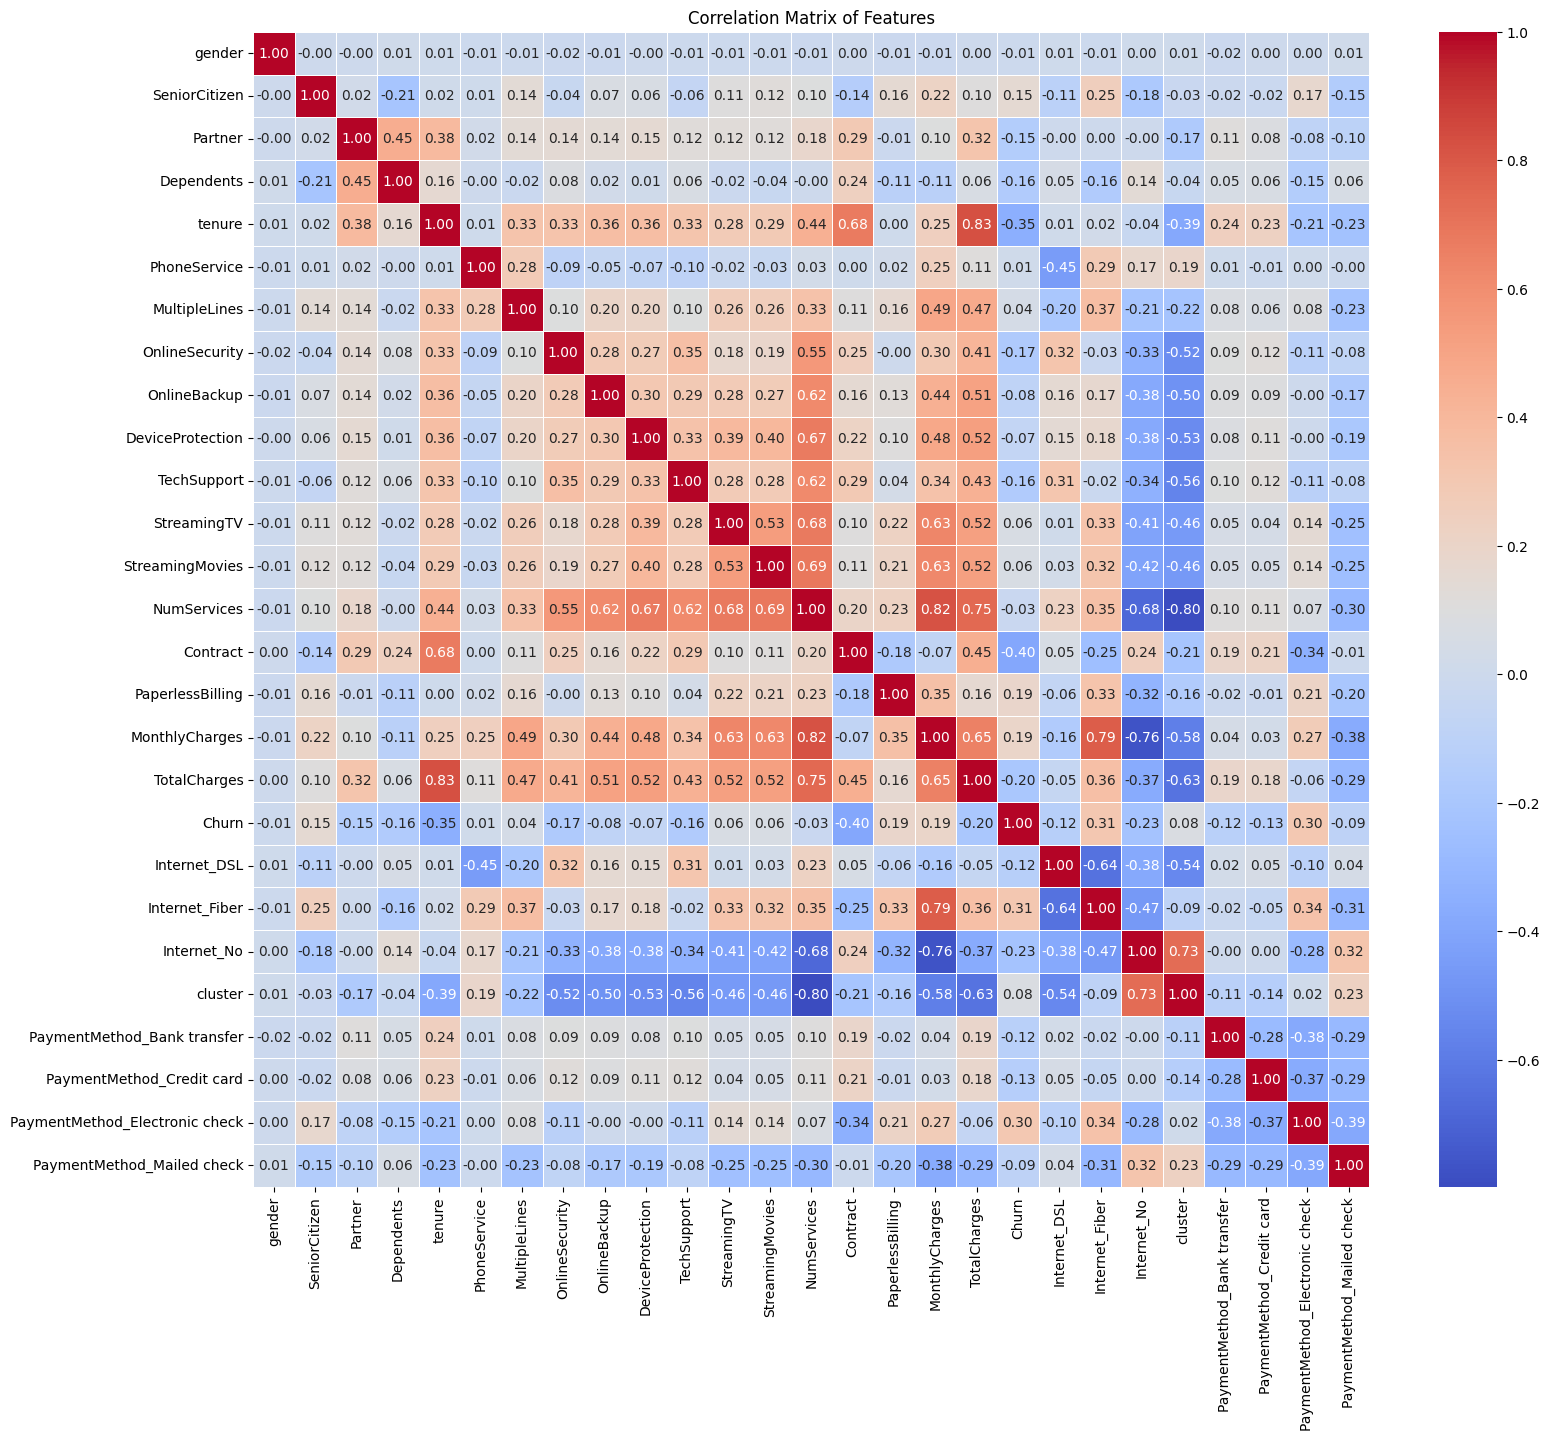

In [279]:
# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Features')
plt.show()

In [280]:
# ============================================================
# EVIDENCE: VIF before dropping MonthlyCharges (documents why it was dropped)
# This is a standalone diagnostic snapshot - kept separate from the final
# feature-selection variables below so it doesn't get overwritten.
# ============================================================

pretrim_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
     'Contract', 'PaperlessBilling', 'MonthlyCharges', 'Internet_DSL', 'Internet_Fiber',
    'PaymentMethod_Credit card', 'PaymentMethod_Bank transfer',
    'PaymentMethod_Electronic check'
]

X_pretrim = df[pretrim_features].copy()
X_pretrim_const = sm.add_constant(X_pretrim)

vif_before_df = pd.DataFrame()
vif_before_df['feature'] = X_pretrim_const.columns
vif_before_df['VIF'] = [
    variance_inflation_factor(X_pretrim_const.values, i)
    for i in range(X_pretrim_const.shape[1])
]
vif_before_df = vif_before_df[vif_before_df['feature'] != 'const']
vif_before_df = vif_before_df.sort_values('VIF', ascending=False).reset_index(drop=True)

print("VIF BEFORE dropping MonthlyCharges/NumServices/TotalCharges/Internet_No/Mailed-check dummy:")
display(vif_before_df)

VIF BEFORE dropping MonthlyCharges/NumServices/TotalCharges/Internet_No/Mailed-check dummy:


,feature,VIF
0,MonthlyCharges,863.656070
1,Internet_Fiber,592.079189
2,Internet_DSL,138.588950
3,PhoneService,34.891820
4,StreamingMovies,24.150842
5,StreamingTV,24.075637
6,MultipleLines,7.279546
7,DeviceProtection,6.905536
8,OnlineBackup,6.761574
9,TechSupport,6.459829


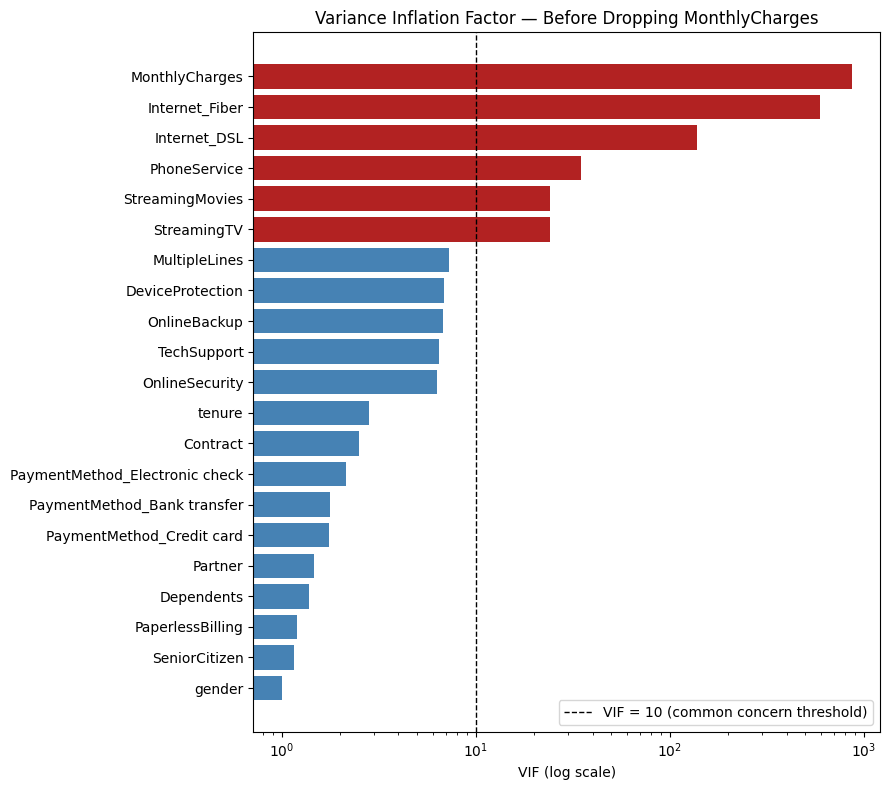

In [281]:
plot_df = vif_before_df.sort_values('VIF', ascending=True)
colors = ['firebrick' if v > 10 else 'steelblue' for v in plot_df['VIF']]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(plot_df['feature'], plot_df['VIF'], color=colors)
ax.set_xscale('log')
ax.axvline(10, color='black', linestyle='--', linewidth=1, label='VIF = 10 (common concern threshold)')
ax.set_xlabel('VIF (log scale)')
ax.set_title('Variance Inflation Factor — Before Dropping MonthlyCharges')
ax.legend()
plt.tight_layout()
plt.show()

Based on the correlation analysis and the specified requirements, the following features have been selected for the models, and certain variables have been dropped for the reasons stated below:

**Features Kept:**
*   `gender`
*   `SeniorCitizen`
*   `Partner`
*   `Dependents`
*   `tenure`
*   `PhoneService`
*   `MultipleLines`
*   `OnlineSecurity`
*   `OnlineBackup`
*   `DeviceProtection`
*   `TechSupport`
*   `StreamingTV`
*   `StreamingMovies`
*   `Contract`
*   `PaperlessBilling`
*   `Internet_DSL`
*   `Internet_Fiber`
*   `PaymentMethod_Credit card`
*   `PaymentMethod_Bank transfer`
*   `PaymentMethod_Electronic check`

**Features Dropped (and reasons):**
*   `cluster`: It's a K-means label derived from other variables, not an independent feature.
*   `TotalCharges`: Mechanically redundant with `tenure` multiplied by `MonthlyCharges` (high correlation), leading to multicollinearity.
*   `NumServices`: It's a sum of individual service add-on columns, double-counting the signal. Individual service flags are kept.
*   `MonthlyCharges`: Has high corelation with the kind of internet selected and also the number of services because you would pay more for better internet and more services.
*   `Internet_No`: Causes perfect multicollinearity (dummy variable trap) when `Internet_DSL` and `Internet_Fiber` are also present, as 'No internet' becomes the implied reference category.
*   `PaymentMethod_Mailed check`: Causes perfect multicollinearity (dummy variable trap) with the other payment types.
*   `customerID`: Unique identifier, no predictive power.
*   `tenure_bucket`: Redundant with the continuous `tenure` feature.

In [282]:
selected_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling',
    'Internet_DSL', 'Internet_Fiber',
    'PaymentMethod_Credit card', 'PaymentMethod_Bank transfer', 'PaymentMethod_Electronic check'
]

# Define target variable
X = df[selected_features]
y = df['Churn']

print(f"Final selected features for the model: {selected_features}")
print(f"Shape of X (features): {X.shape}")
print(f"Shape of y (target): {y.shape}")

Final selected features for the model: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'Internet_DSL', 'Internet_Fiber', 'PaymentMethod_Credit card', 'PaymentMethod_Bank transfer', 'PaymentMethod_Electronic check']
Shape of X (features): (7032, 20)
Shape of y (target): (7032,)


## Data Splitting and Scaling

In [283]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45952, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (5625, 20)
X_test shape: (1407, 20)
y_train shape: (5625,)
y_test shape: (1407,)


In [284]:
# Identify numerical columns for scaling
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

# Identify boolean columns that were not part of numerical_cols
# (This is important to avoid double processing if a boolean-like column was already in numerical_cols)
boolean_cols = [col for col in X.columns if X[col].dtype == 'bool' and col not in numerical_cols]

# Initialize StandardScaler
scaler = StandardScaler()

# Scale numerical features in training and test sets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_scaled[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_scaled[numerical_cols])

# Convert remaining boolean columns to integer (0 or 1)
for col in boolean_cols:
    X_train_scaled[col] = X_train_scaled[col].astype(int)
    X_test_scaled[col] = X_test_scaled[col].astype(int)

display(X_train_scaled.head())


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,Internet_DSL,Internet_Fiber,PaymentMethod_Credit card,PaymentMethod_Bank transfer,PaymentMethod_Electronic check
1097,-1.017034,-0.442195,1.028678,1.505507,-0.509323,0.328871,-0.854228,-0.635999,-0.726431,-0.720728,-0.640412,-0.784803,-0.789542,-0.827963,-1.222932,-0.723007,-0.881619,0,0,1
5391,-1.017034,-0.442195,-0.972122,-0.664228,0.022115,0.328871,-0.854228,-0.635999,-0.726431,-0.720728,-0.640412,-0.784803,-0.789542,-0.827963,0.817707,-0.723007,1.134277,0,1,0
5016,0.983251,-0.442195,1.028678,-0.664228,1.616431,0.328871,1.170648,-0.635999,-0.726431,-0.720728,-0.640412,-0.784803,-0.789542,1.570230,-1.222932,-0.723007,-0.881619,0,0,0
5436,0.983251,-0.442195,1.028678,1.505507,1.207632,0.328871,1.170648,-0.635999,-0.726431,1.387486,-0.640412,1.274206,-0.789542,1.570230,0.817707,-0.723007,1.134277,1,0,0
188,-1.017034,-0.442195,-0.972122,-0.664228,-0.795483,0.328871,-0.854228,-0.635999,-0.726431,-0.720728,-0.640412,-0.784803,-0.789542,0.371134,-1.222932,-0.723007,-0.881619,0,0,1


In [285]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add a constant column to the training features for VIF calculation
X_train_const = sm.add_constant(X_train_scaled) # Using X_train_scaled after the previous scaling step

# Calculate VIF for each feature in the training set with the constant
vif_data = pd.DataFrame()
vif_data['feature'] = X_train_const.columns

# Exclude the 'const' column itself from VIF calculation and display
vif_data['VIF'] = [variance_inflation_factor(X_train_const.values, i)
                   for i in range(X_train_const.shape[1])]

# Filter out the VIF for the constant term as it's not a feature
vif_data = vif_data[vif_data['feature'] != 'const']

# Sort the results by VIF in descending order
vif_data = vif_data.sort_values(by='VIF', ascending=False)

print("Variance Inflation Factor (VIF) for features (sorted descending):\n")
display(vif_data)

Variance Inflation Factor (VIF) for features (sorted descending):



,feature,VIF
17,Internet_Fiber,4.094192
16,Internet_DSL,3.558324
5,tenure,2.807681
14,Contract,2.534608
20,PaymentMethod_Electronic check,2.172566
19,PaymentMethod_Bank transfer,1.820325
18,PaymentMethod_Credit card,1.764437
12,StreamingTV,1.637279
13,StreamingMovies,1.631363
11,TechSupport,1.493893


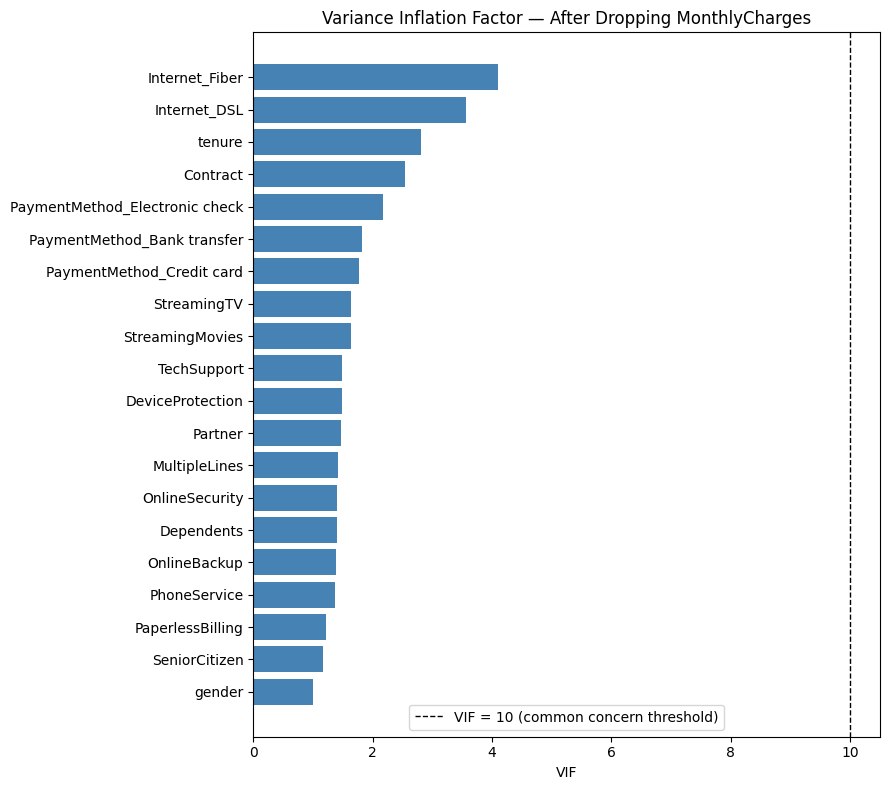

In [307]:
plot_df_after = vif_data.sort_values('VIF', ascending=True)
colors_after = ['firebrick' if v > 10 else 'steelblue' for v in plot_df_after['VIF']]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(plot_df_after['feature'], plot_df_after['VIF'], color=colors_after)
ax.axvline(10, color='black', linestyle='--', linewidth=1, label='VIF = 10 (common concern threshold)')
ax.set_xlabel('VIF')
ax.set_title('Variance Inflation Factor — After Dropping MonthlyCharges')
ax.legend()
plt.tight_layout()
plt.show()

## Logistic Regression Model


In [287]:
# Add a constant to the training data for statsmodels
X_train_const_logit = sm.add_constant(X_train_scaled)

# Fit the logistic regression model
logit_model = sm.Logit(y_train, X_train_const_logit)
result = logit_model.fit()

# Print the model summary
print(result.summary())


Optimization terminated successfully.
         Current function value: 0.415232
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 5625
Model:                          Logit   Df Residuals:                     5604
Method:                           MLE   Df Model:                           20
Date:                Mon, 28 Sep 2026   Pseudo R-squ.:                  0.2829
Time:                        00:41:14   Log-Likelihood:                -2335.7
converged:                       True   LL-Null:                       -3257.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -1.7664      0.092    -19.180     

### Model Evaluation on Test Set

Accuracy: 0.7982
Precision: 0.6364
Recall: 0.5615
AUC Score: 0.8416


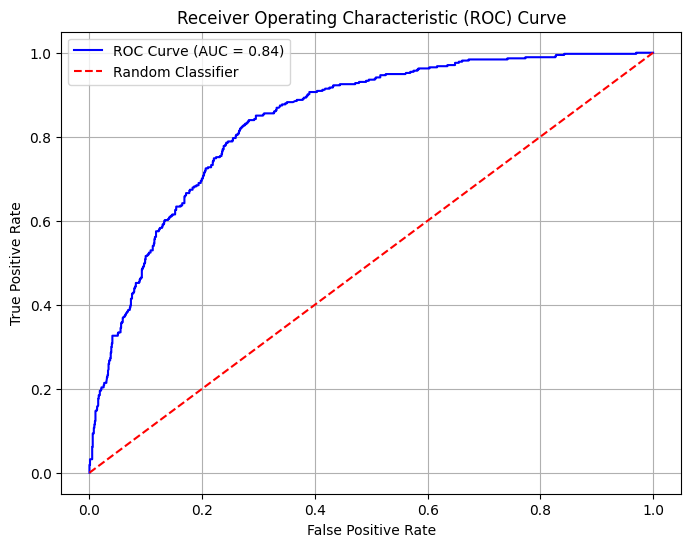


Confusion Matrix:
[[913 120]
 [164 210]]


In [288]:
# Add a constant to the test data for prediction
X_test_const_logit = sm.add_constant(X_test_scaled)

# Predict probabilities on the test set
y_pred_proba = result.predict(X_test_const_logit.values) # Added .values here

# Convert probabilities to binary predictions using a threshold (e.g., 0.5)
y_pred = (y_pred_proba >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"AUC Score: {auc_score:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid(True)
plt.show()

# Print Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(conf_matrix)


In [289]:
# Get p-values from the model result
p_values = result.pvalues

# Create a DataFrame for p-values, excluding the intercept
p_values_df = pd.DataFrame({'feature': p_values.index, 'p_value': p_values.values})
p_values_df = p_values_df[p_values_df['feature'] != 'const']

# Filter for statistically significant variables (p-value < 0.05) and sort by p-value
significant_variables = p_values_df[p_values_df['p_value'] < 0.05].sort_values(by='p_value', ascending=True)

print("\nStatistically Significant Variables (p < 0.05) sorted by p-value ascending:")
display(significant_variables)



Statistically Significant Variables (p < 0.05) sorted by p-value ascending:


,feature,p_value
5,tenure,5.701062e-40
17,Internet_Fiber,1.571521e-26
14,Contract,2.530809e-14
16,Internet_DSL,2.783943e-06
12,StreamingTV,1.154308e-05
8,OnlineSecurity,2.079491e-05
15,PaperlessBilling,1.168726e-04
6,PhoneService,3.387809e-04
11,TechSupport,5.242665e-04
13,StreamingMovies,9.388555e-04


In [290]:
# Extract coefficients from the model result
coefficients = result.params.drop('const') # Exclude the intercept

# Combine significant_variables DataFrame with coefficients
# Ensure both are aligned by feature name
significant_coeffs = significant_variables.set_index('feature').join(coefficients.rename('coefficient'))

# Calculate Odds Ratios
significant_coeffs['odds_ratio'] = np.exp(significant_coeffs['coefficient'])

# Calculate Odds Ratio % Change
significant_coeffs['odds_ratio_percent_change'] = (significant_coeffs['odds_ratio'] - 1) * 100

# Sort by the absolute value of 'odds_ratio_percent_change' descending
final_table = significant_coeffs.sort_values(by='odds_ratio_percent_change', key=abs, ascending=False).reset_index()

# Select and rename columns for the final display
final_table = final_table[['feature', 'coefficient', 'odds_ratio', 'odds_ratio_percent_change']]
final_table.columns = ['Feature', 'Coefficient', 'Odds Ratio', 'Odds Ratio % Change']

print("\nOdds Ratios for Statistically Significant Variables (p < 0.05) sorted by absolute % change:")
display(final_table)


Odds Ratios for Statistically Significant Variables (p < 0.05) sorted by absolute % change:


,Feature,Coefficient,Odds Ratio,Odds Ratio % Change
0,Internet_Fiber,0.791291,2.206243,120.624348
1,tenure,-0.864886,0.421100,-57.890032
2,Contract,-0.547072,0.578641,-42.135859
3,PaymentMethod_Electronic check,0.337788,1.401844,40.184359
4,Internet_DSL,0.334172,1.396783,39.678349
5,StreamingTV,0.191901,1.211551,21.155061
6,PaperlessBilling,0.158846,1.172157,17.215736
7,OnlineSecurity,-0.182217,0.833420,-16.657971
8,StreamingMovies,0.143664,1.154496,15.449575
9,TechSupport,-0.151515,0.859405,-14.059529


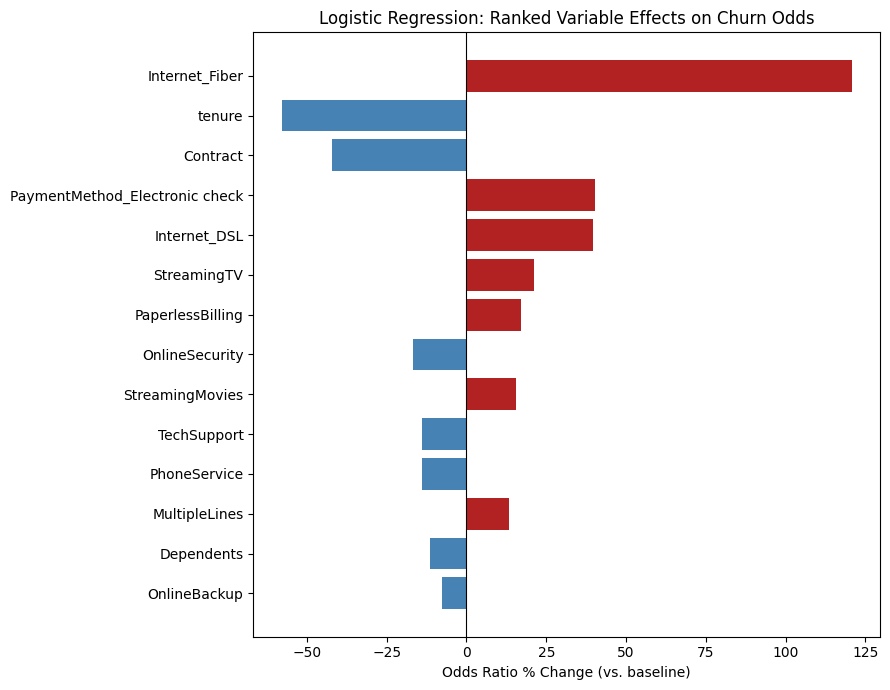

In [314]:
plot_data = significant_coeffs.sort_values('odds_ratio_percent_change', key=abs, ascending=True)
colors = ['firebrick' if v > 0 else 'steelblue' for v in plot_data['odds_ratio_percent_change']]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_data.index, plot_data['odds_ratio_percent_change'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Odds Ratio % Change (vs. baseline)')
ax.set_title('Logistic Regression: Ranked Variable Effects on Churn Odds')
plt.tight_layout()
plt.show()

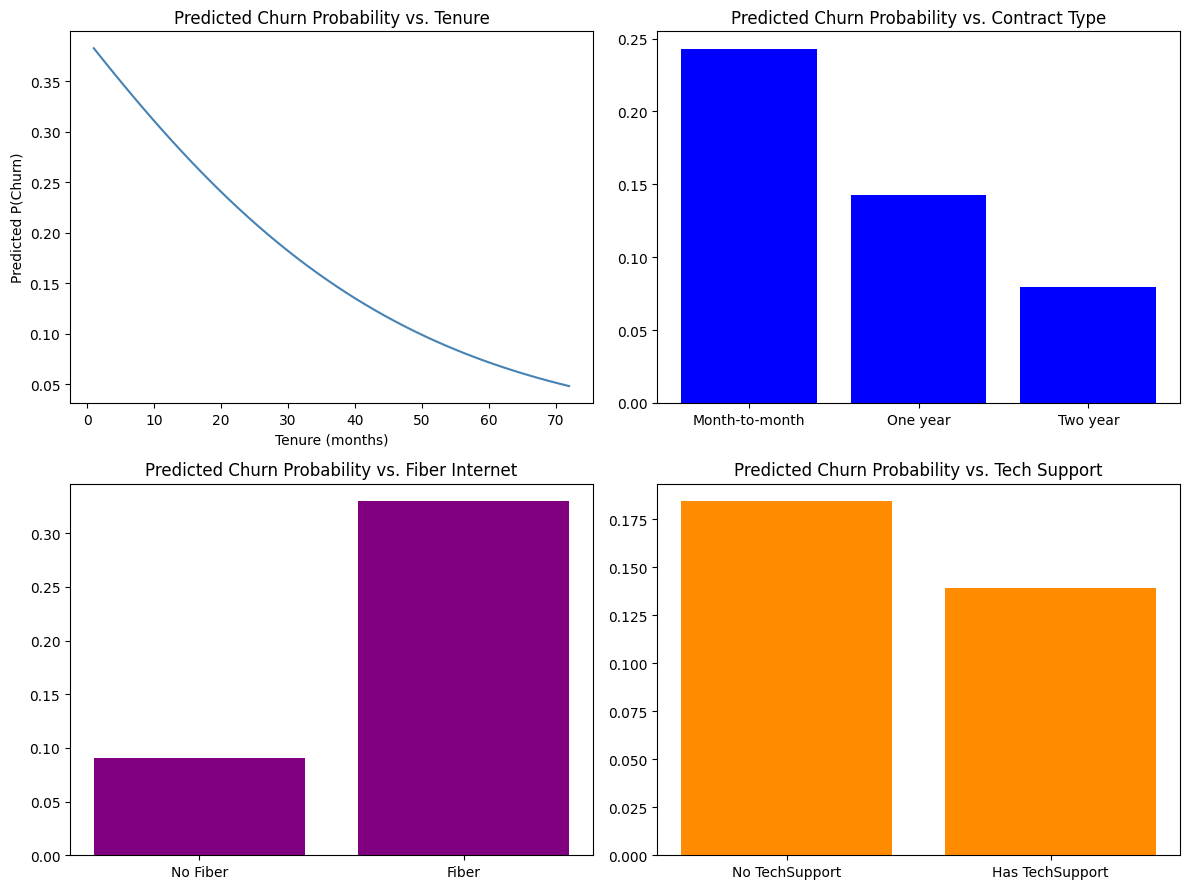

In [292]:
feature_cols = X_test_scaled.columns.tolist()

def get_col_idx(col_name):
    return feature_cols.index(col_name)

def scaled_to_raw(col_name, scaled_val):
    if col_name in numerical_cols:
        idx = numerical_cols.index(col_name)
        return scaled_val * scaler.scale_[idx] + scaler.mean_[idx]
    else:
        return scaled_val

def raw_to_scaled(col_name, raw_val):
    if col_name in numerical_cols:
        idx = numerical_cols.index(col_name)
        return (raw_val - scaler.mean_[idx]) / scaler.scale_[idx]
    else:
        return raw_val

def predict_prob_from_row(row_values):
    row_with_const = np.insert(row_values, 0, 1.0)
    return result.predict(row_with_const.reshape(1, -1))[0]

baseline = X_test_scaled.mean(axis=0).values.copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

tenure_idx = get_col_idx('tenure')
tenure_scaled_range = np.linspace(X_test_scaled['tenure'].min(), X_test_scaled['tenure'].max(), 50)
probs = [predict_prob_from_row((lambda r: (r.__setitem__(tenure_idx, v), r)[1])(baseline.copy())) for v in tenure_scaled_range]
tenure_raw_range = [scaled_to_raw('tenure', v) for v in tenure_scaled_range]
axes[0, 0].plot(tenure_raw_range, probs, color='steelblue')
axes[0, 0].set_title('Predicted Churn Probability vs. Tenure')
axes[0, 0].set_xlabel('Tenure (months)')
axes[0, 0].set_ylabel('Predicted P(Churn)')

contract_idx = get_col_idx('Contract')
contract_labels = ['Month-to-month', 'One year', 'Two year']
probs = []
for raw_val in [0, 1, 2]:
    row = baseline.copy(); row[contract_idx] = raw_to_scaled('Contract', raw_val)
    probs.append(predict_prob_from_row(row))
axes[0, 1].bar(contract_labels, probs, color='blue')
axes[0, 1].set_title('Predicted Churn Probability vs. Contract Type')

fiber_idx = get_col_idx('Internet_Fiber')
probs = []
for raw_val in [0, 1]:
    row = baseline.copy(); row[fiber_idx] = raw_to_scaled('Internet_Fiber', raw_val)
    probs.append(predict_prob_from_row(row))
axes[1, 0].bar(['No Fiber', 'Fiber'], probs, color='purple')
axes[1, 0].set_title('Predicted Churn Probability vs. Fiber Internet')

tech_idx = get_col_idx('TechSupport')
probs = []
for raw_val in [0, 1]:
    row = baseline.copy(); row[tech_idx] = raw_to_scaled('TechSupport', raw_val)
    probs.append(predict_prob_from_row(row))
axes[1, 1].bar(['No TechSupport', 'Has TechSupport'], probs, color='darkorange')
axes[1, 1].set_title('Predicted Churn Probability vs. Tech Support')

plt.tight_layout()
plt.show()

In [293]:
# Sample subscriber scoring - highest and lowest predicted churn risk (test set)
scores_df = pd.DataFrame({
    'predicted_prob': y_pred_proba,
    'actual_churn': y_test.values
}, index=X_test_scaled.index)

top_risk = scores_df.sort_values('predicted_prob', ascending=False).head(5)
low_risk = scores_df.sort_values('predicted_prob', ascending=True).head(5)

print("HIGHEST PREDICTED CHURN RISK:")
display(top_risk)
print("\nLOWEST PREDICTED CHURN RISK:")
display(low_risk)

print("\nRaw feature values - highest risk subscribers:")
display(X_test.loc[top_risk.index])

print("\nRaw feature values - lowest risk subscribers:")
display(X_test.loc[low_risk.index])

def explain_score(customer_id, top_n=6):
    row_scaled = X_test_const_logit.loc[customer_id]
    contributions = result.params * row_scaled
    contributions = contributions.drop('const')

    score = result.params['const'] + contributions.sum()
    prob_manual = np.exp(score) / (1 + np.exp(score))

    print(f"\n--- Customer {customer_id} ---")
    print(f"SCORE (log-odds) = {score:.4f}")
    print(f"P(Churn) = {prob_manual:.4f}   (model predict(): {scores_df.loc[customer_id,'predicted_prob']:.4f})")

    top_contribs = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(top_n)
    print(f"\nTop {top_n} contributing variables:")
    display(top_contribs.to_frame(name='contribution'))

explain_score(top_risk.index[0])
explain_score(low_risk.index[0])

HIGHEST PREDICTED CHURN RISK:


,predicted_prob,actual_churn
2572,0.855637,1
3204,0.855637,1
5273,0.847276,1
6883,0.844350,1
5924,0.843746,1



LOWEST PREDICTED CHURN RISK:


,predicted_prob,actual_churn
5413,0.003628,0
2519,0.003932,0
1838,0.004143,0
6519,0.004238,0
2046,0.004510,0



Raw feature values - highest risk subscribers:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,Internet_DSL,Internet_Fiber,PaymentMethod_Credit card,PaymentMethod_Bank transfer,PaymentMethod_Electronic check
2572,0,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,1,False,False,True
3204,0,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,1,False,False,True
5273,0,0,1,0,3,1,1,0,0,0,0,1,1,0,1,0,1,False,False,True
6883,1,1,1,0,3,1,1,0,1,1,0,1,1,0,1,0,1,False,False,True
5924,1,1,0,0,3,1,1,0,1,1,0,1,1,0,1,0,1,False,False,True


... (2 outputs left out)


--- Customer 2572 ---
SCORE (log-odds) = 1.7795
P(Churn) = 0.8556   (model predict(): 0.8556)

Top 6 contributing variables:


,contribution
tenure,1.112279
Internet_Fiber,0.897544
Contract,0.452955
PaymentMethod_Electronic check,0.337788
StreamingTV,0.244521
Internet_DSL,-0.241609



--- Customer 5413 ---
SCORE (log-odds) = -5.6153
P(Churn) = 0.0036   (model predict(): 0.0036)

Top 6 contributing variables:


,contribution
tenure,-1.256602
Contract,-0.859029
Internet_Fiber,-0.697617
Internet_DSL,0.462197
OnlineSecurity,-0.286506
TechSupport,-0.236590


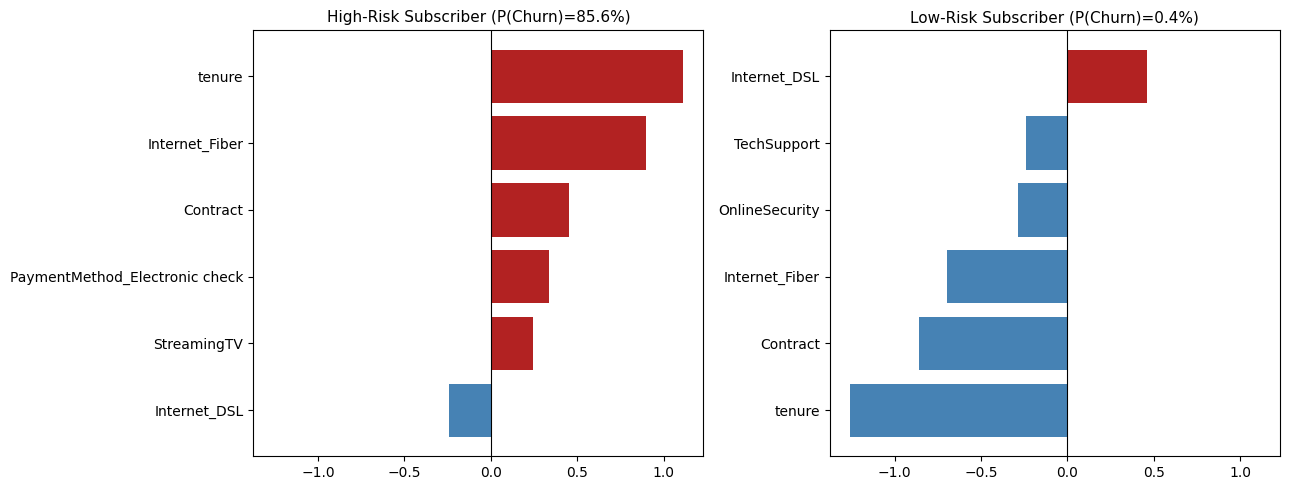

In [294]:
high_risk_contribs = {
    'tenure': 1.112279, 'Internet_Fiber': 0.897544, 'Contract': 0.452955,
    'PaymentMethod_Electronic check': 0.337788, 'StreamingTV': 0.244521, 'Internet_DSL': -0.241609
}
low_risk_contribs = {
    'tenure': -1.256602, 'Contract': -0.859029, 'Internet_Fiber': -0.697617,
    'Internet_DSL': 0.462197, 'OnlineSecurity': -0.286506, 'TechSupport': -0.236590
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

for ax, contribs, title, color in [
    (axes[0], high_risk_contribs, 'High-Risk Subscriber (P(Churn)=85.6%)', 'firebrick'),
    (axes[1], low_risk_contribs, 'Low-Risk Subscriber (P(Churn)=0.4%)', 'steelblue')
]:
    items = sorted(contribs.items(), key=lambda x: x[1])
    labels, values = zip(*items)
    bar_colors = ['firebrick' if v > 0 else 'steelblue' for v in values]
    ax.barh(labels, values, color=bar_colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.show()

## Decision Tree Model

Train (sub) shape: (4218, 20)
Validation shape:  (1407, 20)
Test shape:        (1407, 20)


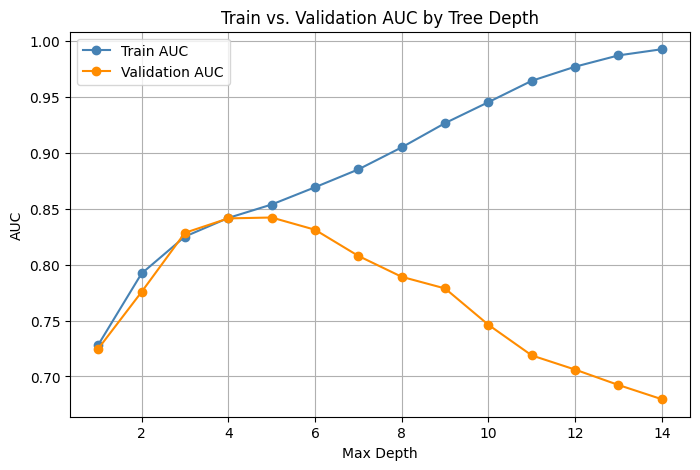

Best depth by validation AUC: 5 (Validation AUC = 0.8421)


In [295]:
# Carve a validation set out of the training set (X_train/y_train are still
# the original 80% training split from cell 12; test set stays untouched)
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=45952, stratify=y_train
)
# Overall split is now ~60% train / 20% validation / 20% test

print(f"Train (sub) shape: {X_train_sub.shape}")
print(f"Validation shape:  {X_val.shape}")
print(f"Test shape:        {X_test.shape}")

# Try a range of depths, fit on sub-train, score on validation only
depths = range(1, 15)
val_aucs = []
train_aucs = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=45952)
    tree.fit(X_train_sub, y_train_sub)
    train_aucs.append(roc_auc_score(y_train_sub, tree.predict_proba(X_train_sub)[:, 1]))
    val_aucs.append(roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1]))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_aucs, marker='o', label='Train AUC', color='steelblue')
plt.plot(depths, val_aucs, marker='o', label='Validation AUC', color='darkorange')
plt.xlabel('Max Depth')
plt.ylabel('AUC')
plt.title('Train vs. Validation AUC by Tree Depth')
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(val_aucs)]
print(f"Best depth by validation AUC: {best_depth} (Validation AUC = {max(val_aucs):.4f})")

In [296]:
# Refit the chosen depth on the FULL training set (sub-train + validation
# combined = original X_train), so no training signal is wasted; validation
# was only used to pick the depth, not to fit the final model

initial_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=45952)
initial_tree.fit(X_train, y_train)

train_acc = accuracy_score(y_train, initial_tree.predict(X_train))
test_acc = accuracy_score(y_test, initial_tree.predict(X_test))
train_auc = roc_auc_score(y_train, initial_tree.predict_proba(X_train)[:, 1])
test_auc = roc_auc_score(y_test, initial_tree.predict_proba(X_test)[:, 1])

print(f"Initial tree (max_depth={best_depth}):")
print(f"  Train accuracy: {train_acc:.4f}   Test accuracy: {test_acc:.4f}")
print(f"  Train AUC:      {train_auc:.4f}   Test AUC:      {test_auc:.4f}")

Initial tree (max_depth=5):
  Train accuracy: 0.7986   Test accuracy: 0.7953
  Train AUC:      0.8527   Test AUC:      0.8278


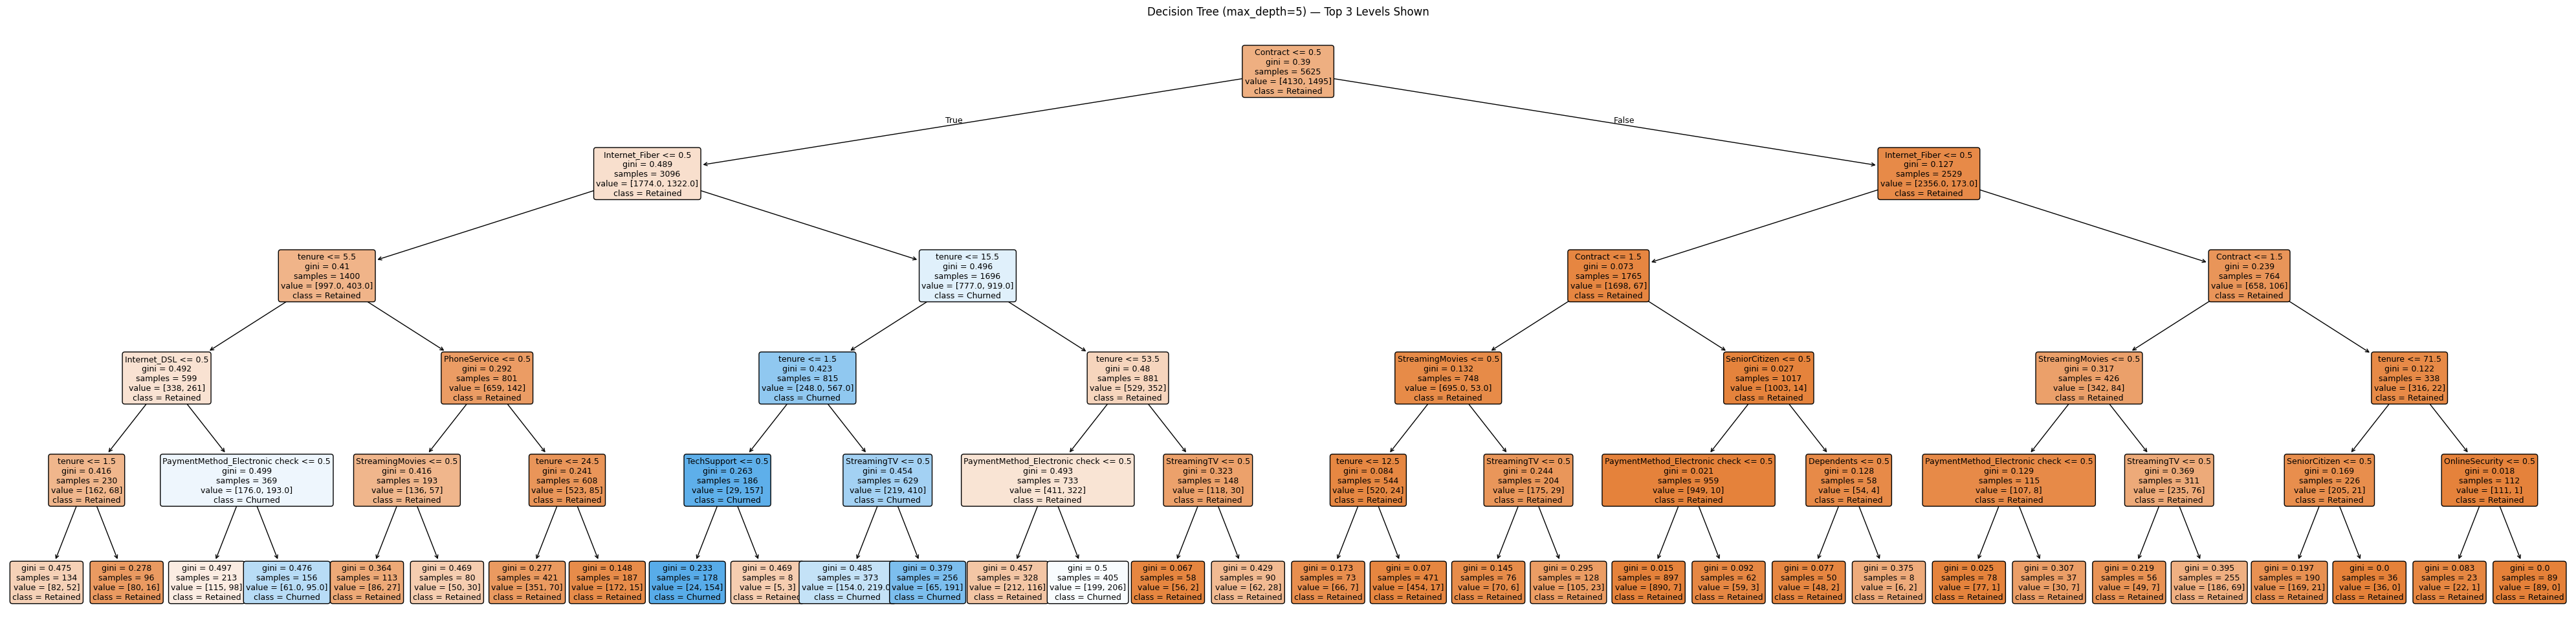

Feature importances (Gini-based, tree-selected variables only):


,importance
Contract,0.526410
tenure,0.219743
Internet_Fiber,0.157324
StreamingTV,0.022904
Internet_DSL,0.020994
PaymentMethod_Electronic check,0.020706
StreamingMovies,0.013924
PhoneService,0.010156
TechSupport,0.005271
SeniorCitizen,0.001597


|--- Contract <= 0.50
|   |--- Internet_Fiber <= 0.50
|   |   |--- tenure <= 5.50
|   |   |   |--- Internet_DSL <= 0.50
|   |   |   |   |--- tenure <= 1.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- tenure >  1.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- Internet_DSL >  0.50
|   |   |   |   |--- PaymentMethod_Electronic check <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- PaymentMethod_Electronic check >  0.50
|   |   |   |   |   |--- class: 1
|   |   |--- tenure >  5.50
|   |   |   |--- PhoneService <= 0.50
|   |   |   |   |--- StreamingMovies <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- StreamingMovies >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- PhoneService >  0.50
|   |   |   |   |--- tenure <= 24.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- tenure >  24.50
|   |   |   |   |   |--- class: 0
|   |--- Internet_Fiber >  0.50
|   |   |--- tenure <= 15.50
|   |   |   |--- tenure <= 1.50
|   |   |   |   |

In [297]:
from sklearn.tree import plot_tree

plt.figure(figsize=(40,10))
plot_tree(
    initial_tree,
    feature_names=X_train.columns,
    class_names=['Retained', 'Churned'],
    filled=True,
    rounded=True,
    fontsize=9,
    # max_depth=3  # show top levels clearly on screen; full tree still saved to file below
)
plt.title(f"Decision Tree (max_depth={best_depth}) — Top 3 Levels Shown")
plt.tight_layout()
plt.savefig('decision_tree_full.png', dpi=150, bbox_inches='tight')  # full depth-5 tree for reference
plt.show()

# Feature importances - which variables the tree actually used, ranked
importances = pd.Series(initial_tree.feature_importances_, index=X_train.columns)
importances = importances[importances > 0].sort_values(ascending=False)

print("Feature importances (Gini-based, tree-selected variables only):")
display(importances.to_frame(name='importance'))

# Print the tree as readable text rules as well - useful for pulling exact split thresholds
from sklearn.tree import export_text
print(export_text(initial_tree, feature_names=list(X_train.columns), max_depth=4))

Down-sampled Comparison Tree

In [298]:
from sklearn.utils import resample

# Down-sample the majority class (Retained/0) in the TRAINING set only
# X_train/y_train are the original full training split from cell 12 - test set untouched
train_data = X_train.copy()
train_data['Churn'] = y_train.values

majority = train_data[train_data['Churn'] == 0]
minority = train_data[train_data['Churn'] == 1]

majority_downsampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=45952
)

train_downsampled = pd.concat([majority_downsampled, minority])
train_downsampled = train_downsampled.sample(frac=1, random_state=45952).reset_index(drop=True)  # shuffle

X_train_down = train_downsampled.drop(columns='Churn')
y_train_down = train_downsampled['Churn']

print(f"Original training set: {len(y_train)} rows, {y_train.mean():.1%} churn")
print(f"Down-sampled training set: {len(y_train_down)} rows, {y_train_down.mean():.1%} churn")

Original training set: 5625 rows, 26.6% churn
Down-sampled training set: 2990 rows, 50.0% churn


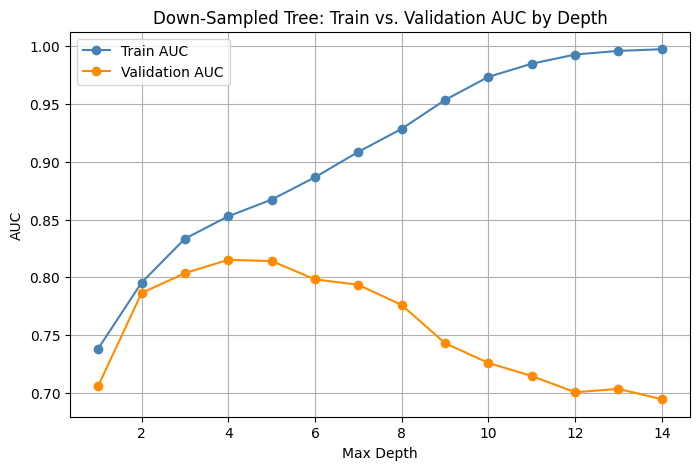

Best depth (down-sampled) by validation AUC: 4 (Validation AUC = 0.8151)


In [299]:
X_train_down_sub, X_val_down, y_train_down_sub, y_val_down = train_test_split(
    X_train_down, y_train_down, test_size=0.25, random_state=45952, stratify=y_train_down
)

depths = range(1, 15)
val_aucs_down = []
train_aucs_down = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=45952)
    tree.fit(X_train_down_sub, y_train_down_sub)
    train_aucs_down.append(roc_auc_score(y_train_down_sub, tree.predict_proba(X_train_down_sub)[:, 1]))
    val_aucs_down.append(roc_auc_score(y_val_down, tree.predict_proba(X_val_down)[:, 1]))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_aucs_down, marker='o', label='Train AUC', color='steelblue')
plt.plot(depths, val_aucs_down, marker='o', label='Validation AUC', color='darkorange')
plt.xlabel('Max Depth')
plt.ylabel('AUC')
plt.title('Down-Sampled Tree: Train vs. Validation AUC by Depth')
plt.legend()
plt.grid(True)
plt.show()

best_depth_down = depths[np.argmax(val_aucs_down)]
print(f"Best depth (down-sampled) by validation AUC: {best_depth_down} (Validation AUC = {max(val_aucs_down):.4f})")

In [300]:
final_tree_down = DecisionTreeClassifier(max_depth=best_depth_down, random_state=45952)
final_tree_down.fit(X_train_down, y_train_down)

# Evaluate on the SAME untouched X_test/y_test as the original tree
test_acc_down = accuracy_score(y_test, final_tree_down.predict(X_test))
test_auc_down = roc_auc_score(y_test, final_tree_down.predict_proba(X_test)[:, 1])
test_precision_down = precision_score(y_test, final_tree_down.predict(X_test))
test_recall_down = recall_score(y_test, final_tree_down.predict(X_test))

print(f"Down-sampled tree (max_depth={best_depth_down}) - Test set performance:")
print(f"  Accuracy:  {test_acc_down:.4f}")
print(f"  Precision: {test_precision_down:.4f}")
print(f"  Recall:    {test_recall_down:.4f}")
print(f"  AUC:       {test_auc_down:.4f}")

# Side-by-side comparison with the original (non-downsampled) tree
test_precision_orig = precision_score(y_test, initial_tree.predict(X_test))
test_recall_orig = recall_score(y_test, initial_tree.predict(X_test))

comparison = pd.DataFrame({
    'Original tree': [test_acc, test_precision_orig, test_recall_orig, test_auc],
    'Down-sampled tree': [test_acc_down, test_precision_down, test_recall_down, test_auc_down]
}, index=['Accuracy', 'Precision', 'Recall', 'AUC'])

print("\nOriginal vs. Down-sampled tree - test set comparison:")
display(comparison)

Down-sampled tree (max_depth=4) - Test set performance:
  Accuracy:  0.7342
  Precision: 0.5000
  Recall:    0.7727
  AUC:       0.8287

Original vs. Down-sampled tree - test set comparison:


,Original tree,Down-sampled tree
Accuracy,0.795309,0.734186
Precision,0.620112,0.500000
Recall,0.593583,0.772727
AUC,0.827795,0.828673


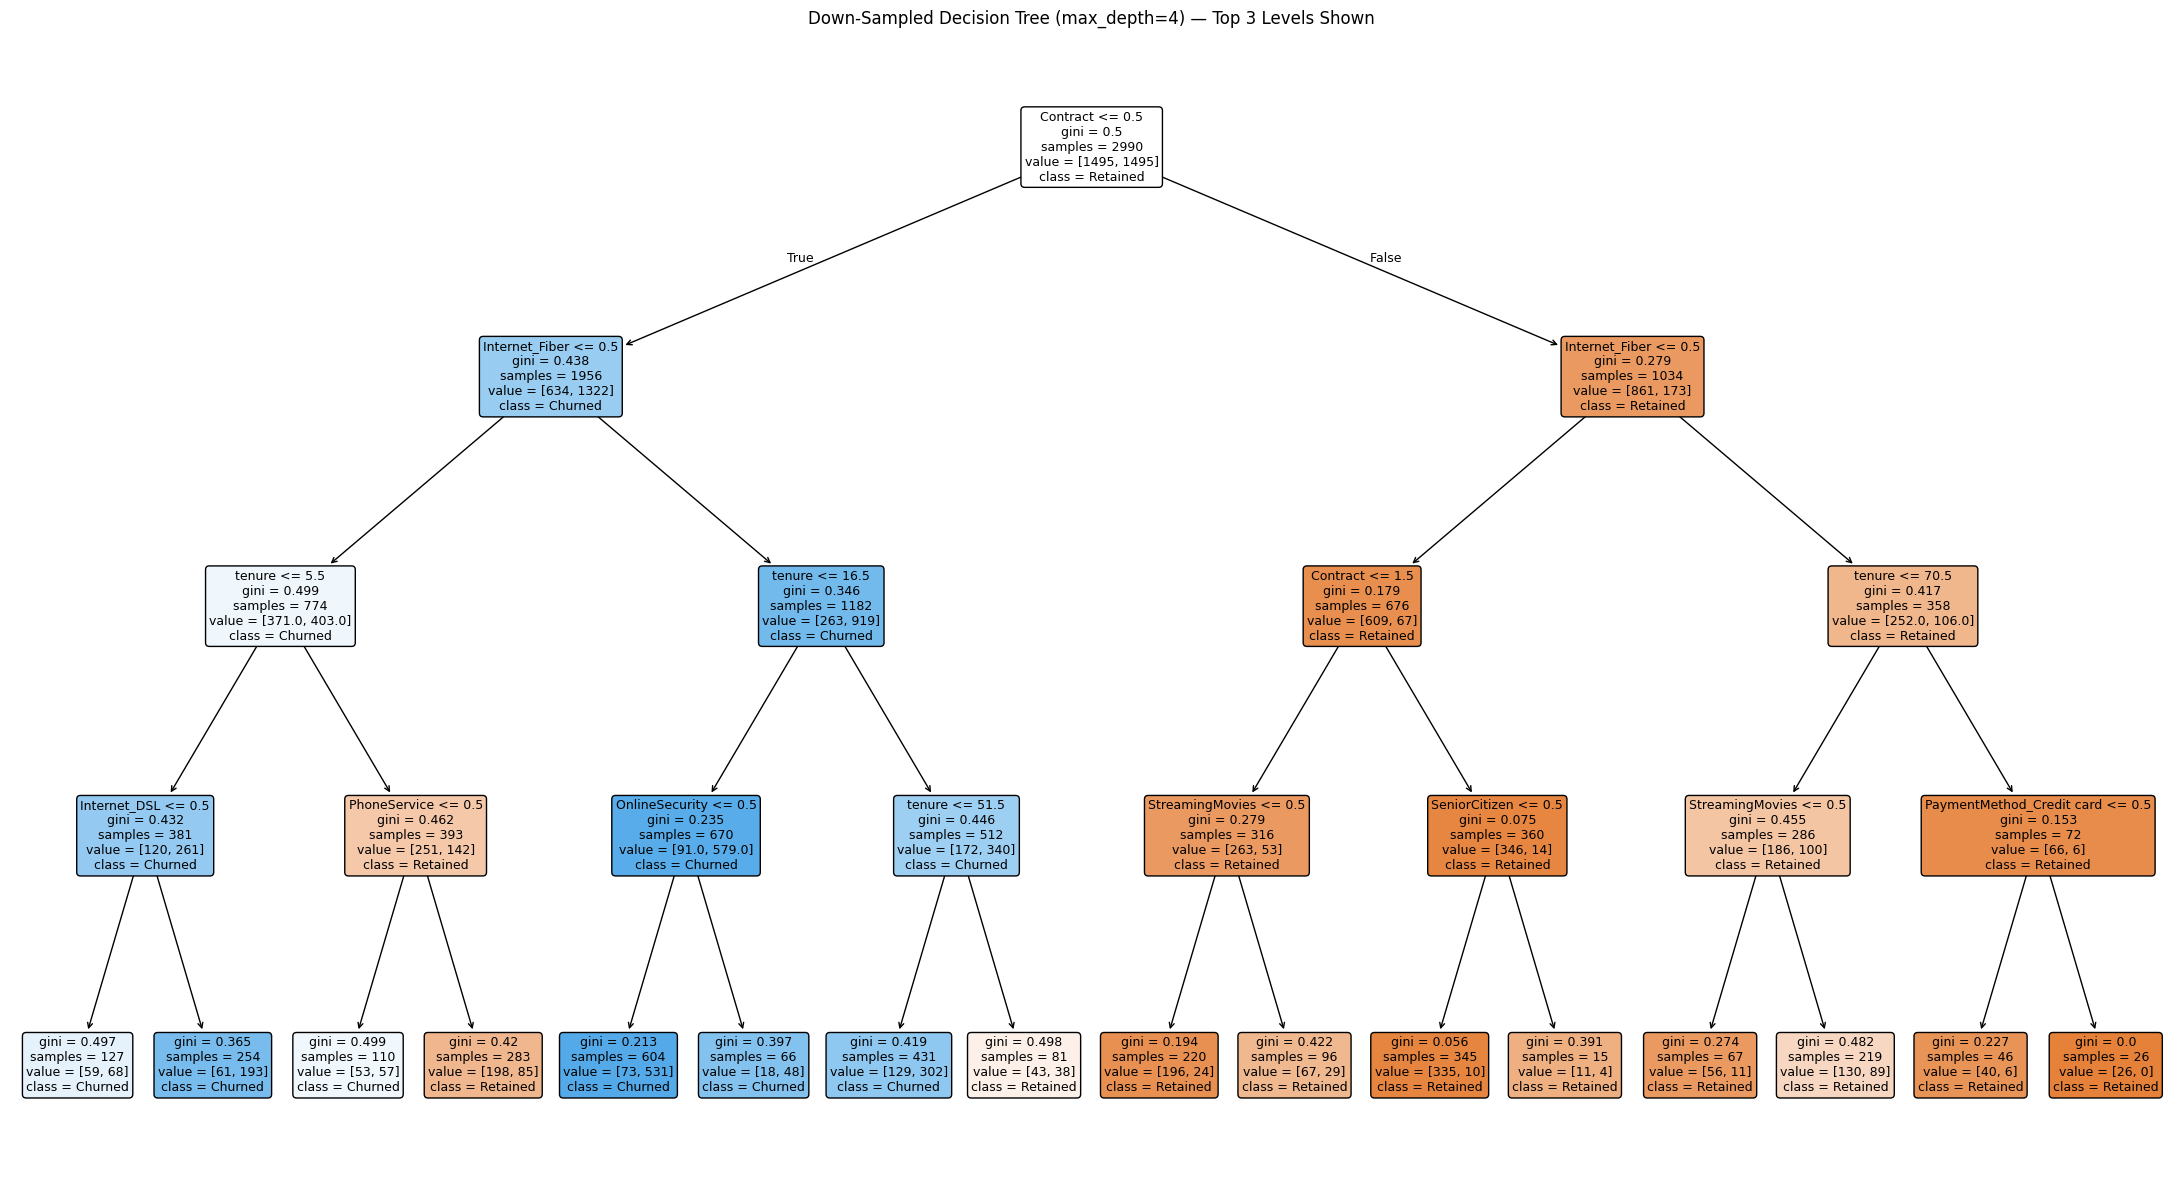

Feature importances (down-sampled tree):


,importance
Contract,0.650367
Internet_Fiber,0.146115
tenure,0.145014
StreamingMovies,0.020123
Internet_DSL,0.015602
PhoneService,0.013753
OnlineSecurity,0.005021
SeniorCitizen,0.002972
PaymentMethod_Credit card,0.001034


|--- Contract <= 0.50
|   |--- Internet_Fiber <= 0.50
|   |   |--- tenure <= 5.50
|   |   |   |--- Internet_DSL <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Internet_DSL >  0.50
|   |   |   |   |--- class: 1
|   |   |--- tenure >  5.50
|   |   |   |--- PhoneService <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- PhoneService >  0.50
|   |   |   |   |--- class: 0
|   |--- Internet_Fiber >  0.50
|   |   |--- tenure <= 16.50
|   |   |   |--- OnlineSecurity <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- OnlineSecurity >  0.50
|   |   |   |   |--- class: 1
|   |   |--- tenure >  16.50
|   |   |   |--- tenure <= 51.50
|   |   |   |   |--- class: 1
|   |   |   |--- tenure >  51.50
|   |   |   |   |--- class: 0
|--- Contract >  0.50
|   |--- Internet_Fiber <= 0.50
|   |   |--- Contract <= 1.50
|   |   |   |--- StreamingMovies <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- StreamingMovies >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Contract >  1.50
|   | 

In [301]:
plt.figure(figsize=(22, 12))
plot_tree(
    final_tree_down,
    feature_names=X_train.columns,
    class_names=['Retained', 'Churned'],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title(f"Down-Sampled Decision Tree (max_depth={best_depth_down}) — Top 3 Levels Shown")
plt.tight_layout()
plt.savefig('decision_tree_downsampled.png', dpi=150, bbox_inches='tight')
plt.show()

importances_down = pd.Series(final_tree_down.feature_importances_, index=X_train.columns)
importances_down = importances_down[importances_down > 0].sort_values(ascending=False)

print("Feature importances (down-sampled tree):")
display(importances_down.to_frame(name='importance'))

print(export_text(final_tree_down, feature_names=list(X_train.columns), max_depth=4))

Model comparison - test set:


,Logistic Regression,Decision Tree (original),Decision Tree (down-sampled)
Accuracy,0.7982,0.7953,0.7342
Precision,0.6364,0.6201,0.5000
Recall,0.5615,0.5936,0.7727
AUC,0.8416,0.8278,0.8287


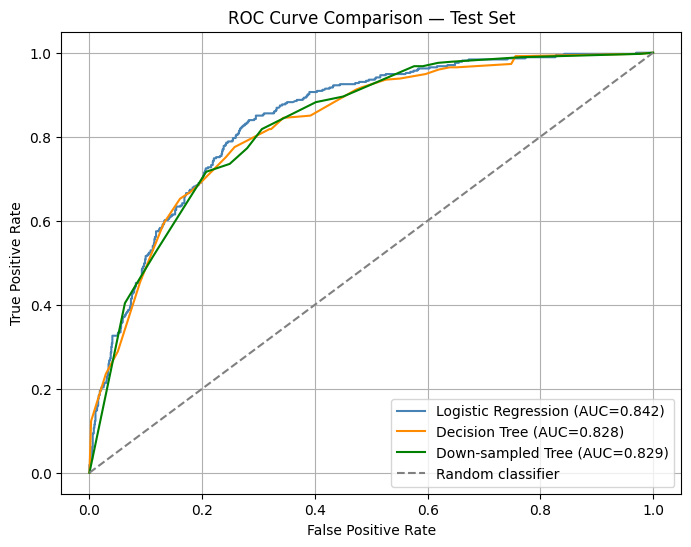

In [302]:
# --- Comparison table: LR, original tree, down-sampled tree ---
def get_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_proba)
    }

lr_metrics = get_metrics(y_test, y_pred, y_pred_proba)
tree_metrics = get_metrics(y_test, final_tree.predict(X_test), final_tree.predict_proba(X_test)[:, 1])
tree_down_metrics = get_metrics(y_test, final_tree_down.predict(X_test), final_tree_down.predict_proba(X_test)[:, 1])

comparison_all = pd.DataFrame({
    'Logistic Regression': lr_metrics,
    'Decision Tree (original)': tree_metrics,
    'Decision Tree (down-sampled)': tree_down_metrics
})

print("Model comparison - test set:")
display(comparison_all.round(4))

# --- ROC curve overlay ---
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba)
fpr_tree, tpr_tree, _ = roc_curve(y_test, final_tree.predict_proba(X_test)[:, 1])
fpr_tree_down, tpr_tree_down, _ = roc_curve(y_test, final_tree_down.predict_proba(X_test)[:, 1])

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={lr_metrics['AUC']:.3f})", color='steelblue')
plt.plot(fpr_tree, tpr_tree, label=f"Decision Tree (AUC={tree_metrics['AUC']:.3f})", color='darkorange')
plt.plot(fpr_tree_down, tpr_tree_down, label=f"Down-sampled Tree (AUC={tree_down_metrics['AUC']:.3f})", color='green')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison — Test Set')
plt.legend()
plt.grid(True)
plt.show()

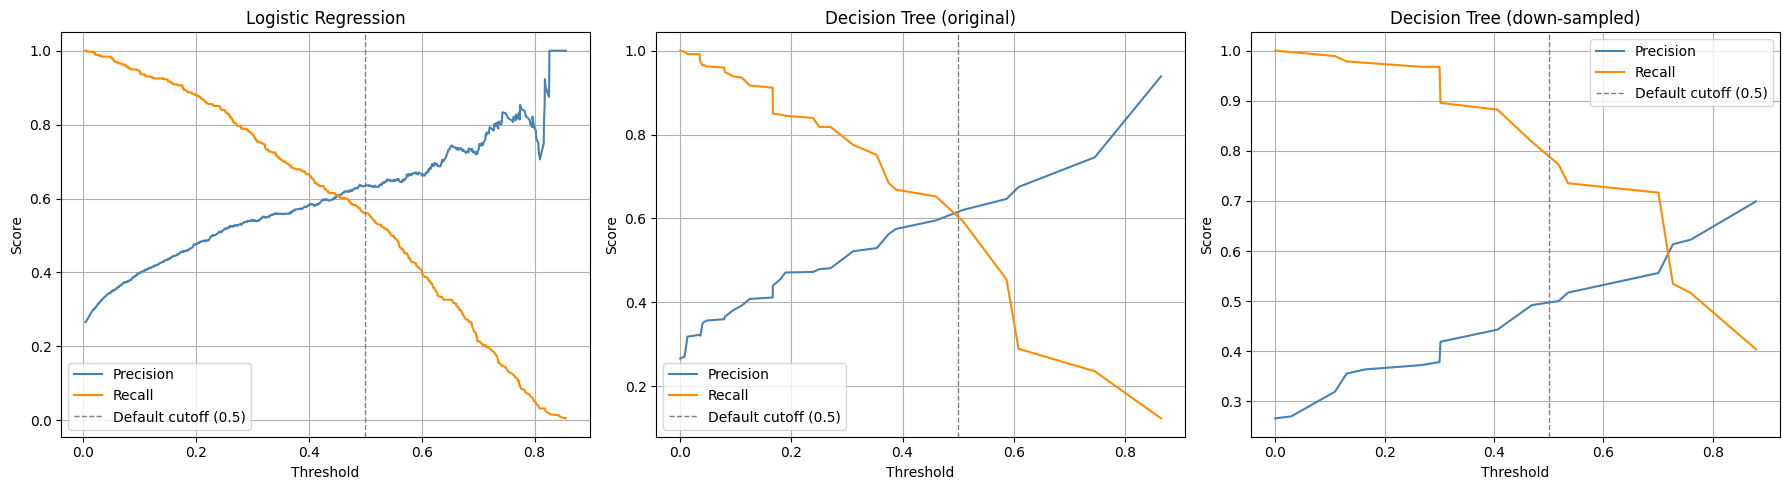

In [303]:
from sklearn.metrics import precision_recall_curve

def plot_precision_recall_vs_threshold(y_true, y_proba, model_name, ax):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    ax.plot(thresholds, precisions[:-1], label='Precision', color='steelblue')
    ax.plot(thresholds, recalls[:-1], label='Recall', color='darkorange')
    ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Default cutoff (0.5)')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Score')
    ax.set_title(model_name)
    ax.legend()
    ax.grid(True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_precision_recall_vs_threshold(y_test, y_pred_proba, 'Logistic Regression', axes[0])
plot_precision_recall_vs_threshold(y_test, final_tree.predict_proba(X_test)[:, 1], 'Decision Tree (original)', axes[1])
plot_precision_recall_vs_threshold(y_test, final_tree_down.predict_proba(X_test)[:, 1], 'Decision Tree (down-sampled)', axes[2])
plt.tight_layout()
plt.show()

## Random Forest Classifier

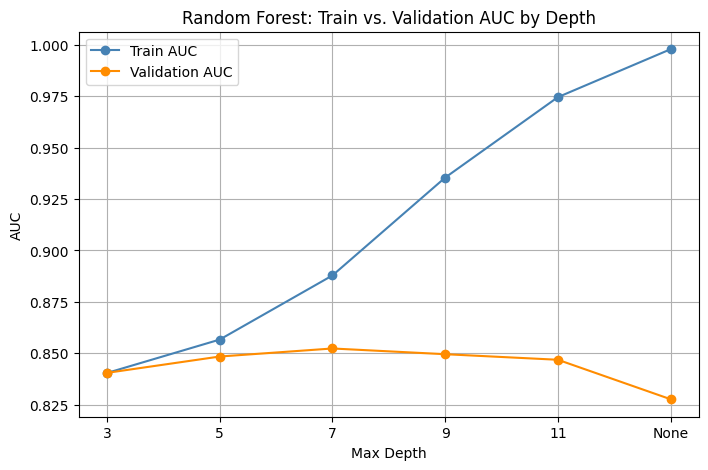

Best max_depth (Random Forest) by validation AUC: 7 (Validation AUC = 0.8523)


In [304]:
depths_rf = [3, 5, 7, 9, 11, None]  # None = unrestricted, as a comparison point
val_aucs_rf = []
train_aucs_rf = []

for d in depths_rf:
    rf_tmp = RandomForestClassifier(n_estimators=300, max_depth=d, random_state=45952)
    rf_tmp.fit(X_train_sub, y_train_sub)  # reusing the same train/val split from the original tree
    train_aucs_rf.append(roc_auc_score(y_train_sub, rf_tmp.predict_proba(X_train_sub)[:, 1]))
    val_aucs_rf.append(roc_auc_score(y_val, rf_tmp.predict_proba(X_val)[:, 1]))

depth_labels = [str(d) if d is not None else 'None' for d in depths_rf]

plt.figure(figsize=(8, 5))
plt.plot(depth_labels, train_aucs_rf, marker='o', label='Train AUC', color='steelblue')
plt.plot(depth_labels, val_aucs_rf, marker='o', label='Validation AUC', color='darkorange')
plt.xlabel('Max Depth')
plt.ylabel('AUC')
plt.title('Random Forest: Train vs. Validation AUC by Depth')
plt.legend()
plt.grid(True)
plt.show()

best_depth_rf = depths_rf[np.argmax(val_aucs_rf)]
print(f"Best max_depth (Random Forest) by validation AUC: {best_depth_rf} (Validation AUC = {max(val_aucs_rf):.4f})")


Model comparison - test set (including Random Forest):


,Logistic Regression,Decision Tree (original),Decision Tree (down-sampled),Random Forest
Accuracy,0.7982,0.7953,0.7342,0.7925
Precision,0.6364,0.6201,0.5000,0.6783
Recall,0.5615,0.5936,0.7727,0.4171
AUC,0.8416,0.8278,0.8287,0.8438


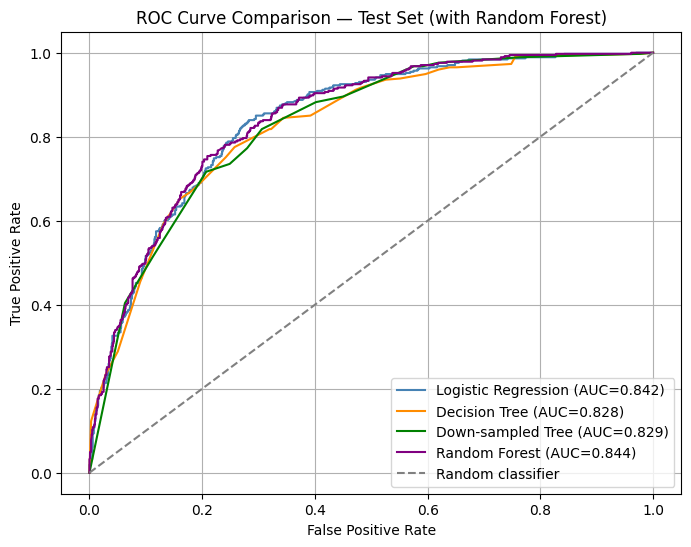


Random Forest feature importances (top 10):


,importance
Contract,0.266021
tenure,0.240423
Internet_Fiber,0.144189
PaymentMethod_Electronic check,0.106960
PaperlessBilling,0.043426
OnlineSecurity,0.035195
TechSupport,0.026592
Dependents,0.025014
Internet_DSL,0.017120
Partner,0.014178


In [305]:
# Refit at the chosen depth on the FULL training set, then evaluate once on the untouched test set
rf = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=45952)
rf.fit(X_train, y_train)

rf_metrics = get_metrics(y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])

comparison_all['Random Forest'] = rf_metrics
print("\nModel comparison - test set (including Random Forest):")
display(comparison_all.round(4))

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={lr_metrics['AUC']:.3f})", color='steelblue')
plt.plot(fpr_tree, tpr_tree, label=f"Decision Tree (AUC={tree_metrics['AUC']:.3f})", color='darkorange')
plt.plot(fpr_tree_down, tpr_tree_down, label=f"Down-sampled Tree (AUC={tree_down_metrics['AUC']:.3f})", color='green')
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={rf_metrics['AUC']:.3f})", color='purple')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison — Test Set (with Random Forest)')
plt.legend()
plt.grid(True)
plt.show()

rf_importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nRandom Forest feature importances (top 10):")
display(rf_importances.head(10).to_frame(name='importance'))

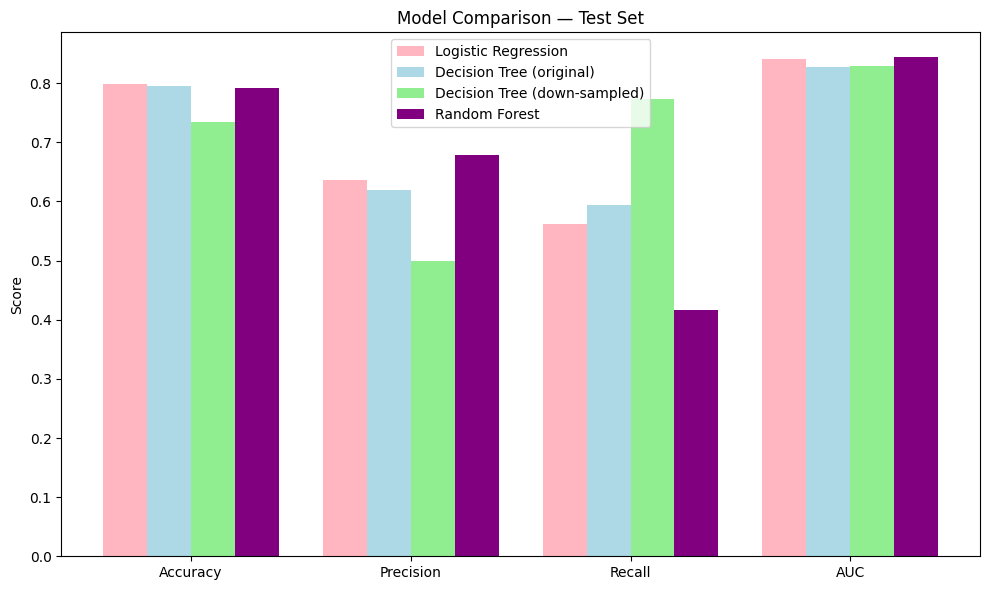

In [312]:
metrics = ['Accuracy', 'Precision', 'Recall', 'AUC']
models = comparison_all.columns.tolist()
x = np.arange(len(metrics))
width = 0.2
colors = ['lightpink', 'lightblue', 'lightgreen', 'purple']

fig, ax = plt.subplots(figsize=(10, 6))
for i, model in enumerate(models):
    values = comparison_all[model].values
    ax.bar(x + i * width, values, width, label=model, color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Test Set')
ax.legend()
plt.tight_layout()
plt.show()